In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from fontTools import subset
from pandas.core.dtypes import astype

df = pd.read_csv("Kolkata_House_Prediction_100.csv")
print(df.head())

     location  area_sqft  bedrooms  bathrooms  stories  price_inr
0    New Town        702         6          3        2    4442256
1    Rajarhat       3616         1          5        1   33762592
2  Tollygunge        730         1          1        2    4675650
3      Howrah       3065         1          5        2   31768725
4      Howrah       2318         2          4        3   25799340


In [3]:
print(df.shape)

(100, 6)


In [4]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   location   100 non-null    str  
 1   area_sqft  100 non-null    int64
 2   bedrooms   100 non-null    int64
 3   bathrooms  100 non-null    int64
 4   stories    100 non-null    int64
 5   price_inr  100 non-null    int64
dtypes: int64(5), str(1)
memory usage: 4.8 KB
None


In [5]:
print(df.describe())

         area_sqft    bedrooms   bathrooms    stories     price_inr
count   100.000000  100.000000  100.000000  100.00000  1.000000e+02
mean   2364.310000    3.290000    3.140000    2.34000  1.906621e+07
std    1023.761353    1.793901    1.490847    1.08451  9.605484e+06
min     601.000000    1.000000    1.000000    1.00000  3.177708e+06
25%    1498.250000    2.000000    2.000000    1.00000  1.116498e+07
50%    2370.500000    3.000000    3.000000    2.00000  1.822728e+07
75%    3320.750000    5.000000    5.000000    3.00000  2.659744e+07
max    3997.000000    6.000000    5.000000    4.00000  3.774952e+07


In [12]:
#data clean

df["location"]=df["location"].str.strip().str.title()
if df["price_inr"].dtype =="object":
    df["price_inr"] = df["price_inr"].str.replace(",","").astype(float)
df["bathrooms"]=df["bathrooms"].fillna(df["bathrooms"].median())
df["stories"]=df["stories"].fillna(1)
df.dropna(subset=["location","area_sqft","price_inr"],inplace=  True)
df.drop_duplicates(inplace=True)

C:\Users\~User~\AppData\Local\Temp\ipykernel_10372\574684092.py:8: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=["location","area_sqft","price_inr"],inplace=  True)
C:\Users\~User~\AppData\Local\Temp\ipykernel_10372\574684092.py:9: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


In [22]:
#feature Engineering
df["price_per_sqft"]=(df["price_inr"]/df["area_sqft"]).round(2)
df["price_lakhs"]=(df["price_inr"]/100000).round(2)
df["size_category"] = pd.cut(
    df["area_sqft"],
    bins=[0, 1000, 2000, float("inf")],
    labels=["Compact", "Standard", "Spacious"]
)


In [19]:
affordable_3bhk = df[(df["bedrooms"]>=3) & ( df["price_inr"]<=10000000)]
target_area = df[df["location"].isin(["New Town","Salt Lake","Ballygung"])]
top_10=df.sort_values(by="price_inr",ascending=False).head(10)

In [24]:
# Compare average price, area, and rate per sqft by location
location_summary = df.groupby("location").agg(
    listing_count=("price_inr", "count"),
    avg_price_lakhs=("price_lakhs", "mean"),
    avg_area_sqft=("area_sqft", "mean"),
    avg_rate_per_sqft=("price_per_sqft", "mean")
).round(2).sort_values(by="avg_price_lakhs", ascending=False).reset_index()

print(location_summary)

# Check average price by bedroom count (1 BHK, 2 BHK, 3 BHK, etc.)
bhk_summary = df.groupby("bedrooms")["price_lakhs"].agg(["count", "mean", "median"]).round(2)

     location  listing_count  avg_price_lakhs  avg_area_sqft  \
0   Salt Lake              7           212.52        2978.57   
1    Jadavpur             12           207.36        2803.00   
2      Behala             10           204.79        2325.80   
3    Rajarhat             10           201.37        2426.20   
4       Garia              9           190.66        2459.78   
5      Howrah             16           185.97        2154.12   
6     Dum Dum              6           185.26        2192.83   
7    New Town             14           179.29        2125.43   
8  Tollygunge             12           177.60        2200.42   
9  Ballygunge              4           146.12        2125.75   

   avg_rate_per_sqft  
0            7269.29  
1            7174.75  
2            8753.40  
3            8706.50  
4            7931.44  
5            8562.81  
6            8037.83  
7            8057.07  
8            7906.17  
9            6564.75  


In [26]:
df.to_csv("clean_Housing_data.csv",index=False)
location_summary.to_csv("location_market_summary.csv",index=False)

C:\Users\~User~\AppData\Local\Temp\ipykernel_10372\2894646800.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\~User~\AppData\Local\Temp\ipykernel_10372\2894646800.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


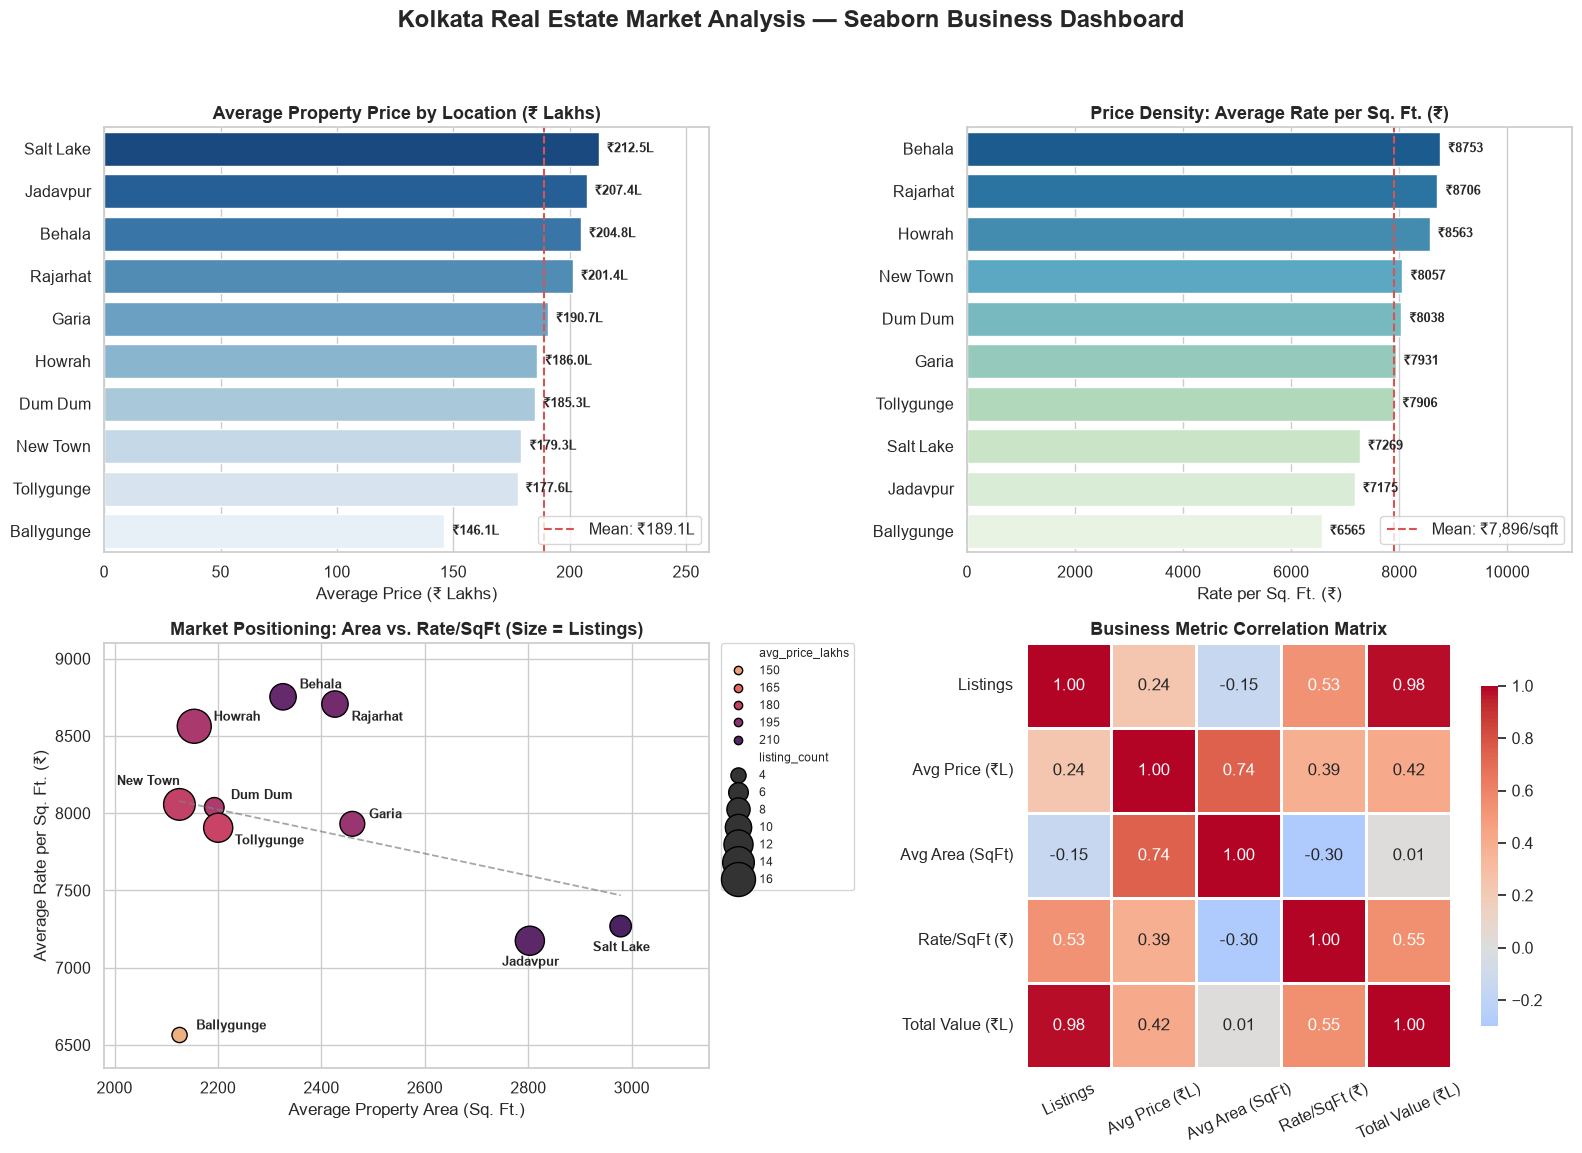

In [30]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load data and compute total market value per location
df = pd.read_csv("location_market_summary.csv")
df["total_inventory_lakhs"] = df["listing_count"] * df["avg_price_lakhs"]

# Configure Seaborn theme
sns.set_theme(style="whitegrid", font_scale=1.05)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("Kolkata Real Estate Market Analysis — Seaborn Business Dashboard", fontsize=17, fontweight="bold", y=0.98)

# 1. Seaborn Barplot: Average Property Price by Location
df_price = df.sort_values("avg_price_lakhs", ascending=False)
sns.barplot(
    data=df_price,
    x="avg_price_lakhs",
    y="location",
    palette="Blues_r",
    ax=axes[0, 0]
)
axes[0, 0].axvline(df["avg_price_lakhs"].mean(), color="#d9534f", linestyle="--", linewidth=1.5, label=f"Mean: ₹{df['avg_price_lakhs'].mean():.1f}L")
axes[0, 0].set_title("Average Property Price by Location (₹ Lakhs)", fontsize=13, fontweight="bold")
axes[0, 0].set_xlabel("Average Price (₹ Lakhs)")
axes[0, 0].set_ylabel("")
axes[0, 0].set_xlim(0, 260)
axes[0, 0].legend(loc="lower right", frameon=True, facecolor="white")
for container in axes[0, 0].containers:
    axes[0, 0].bar_label(container, fmt=" ₹%.1fL", padding=3, fontsize=9.5, fontweight="bold")

# 2. Seaborn Barplot: Price Density (Rate per Sq. Ft.)
df_rate = df.sort_values("avg_rate_per_sqft", ascending=False)
sns.barplot(
    data=df_rate,
    x="avg_rate_per_sqft",
    y="location",
    palette="GnBu_r",
    ax=axes[0, 1]
)
axes[0, 1].axvline(df["avg_rate_per_sqft"].mean(), color="#d9534f", linestyle="--", linewidth=1.5, label=f"Mean: ₹{df['avg_rate_per_sqft'].mean():,.0f}/sqft")
axes[0, 1].set_title("Price Density: Average Rate per Sq. Ft. (₹)", fontsize=13, fontweight="bold")
axes[0, 1].set_xlabel("Rate per Sq. Ft. (₹)")
axes[0, 1].set_ylabel("")
axes[0, 1].set_xlim(0, 11200)
axes[0, 1].legend(loc="lower right", frameon=True, facecolor="white")
for container in axes[0, 1].containers:
    axes[0, 1].bar_label(container, fmt=" ₹%.0f", padding=3, fontsize=9.5, fontweight="bold")

# 3. Seaborn Regression + Scatter Plot: Area vs. Rate per Sq. Ft.
sns.regplot(
    data=df,
    x="avg_area_sqft",
    y="avg_rate_per_sqft",
    scatter=False,
    ci=None,
    color="gray",
    line_kws={"linestyle": "--", "linewidth": 1.3, "alpha": 0.7},
    ax=axes[1, 0]
)
sns.scatterplot(
    data=df,
    x="avg_area_sqft",
    y="avg_rate_per_sqft",
    size="listing_count",
    hue="avg_price_lakhs",
    sizes=(120, 600),
    palette="flare",
    edgecolor="black",
    linewidth=1,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Market Positioning: Area vs. Rate/SqFt (Size = Listings)", fontsize=13, fontweight="bold")
axes[1, 0].set_xlabel("Average Property Area (Sq. Ft.)")
axes[1, 0].set_ylabel("Average Rate per Sq. Ft. (₹)")
axes[1, 0].set_xlim(1980, 3150)
axes[1, 0].set_ylim(6350, 9100)
axes[1, 0].legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0, frameon=True, fontsize=8.5)

offsets = {
    "Salt Lake": (-20, -18), "Jadavpur": (-20, -18), "Behala": (12, 6),
    "Rajarhat": (12, -12), "Garia": (12, 4), "Howrah": (14, 4),
    "Dum Dum": (12, 6), "New Town": (-45, 14), "Tollygunge": (12, -12),
    "Ballygunge": (12, 4)
}
for _, row in df.iterrows():
    dx, dy = offsets.get(row["location"], (8, 8))
    axes[1, 0].annotate(
        row["location"],
        (row["avg_area_sqft"], row["avg_rate_per_sqft"]),
        xytext=(dx, dy),
        textcoords="offset points",
        fontsize=9,
        fontweight="bold"
    )

# 4. Seaborn Heatmap: Correlation Matrix
corr_cols = ["listing_count", "avg_price_lakhs", "avg_area_sqft", "avg_rate_per_sqft", "total_inventory_lakhs"]
corr_labels = ["Listings", "Avg Price (₹L)", "Avg Area (SqFt)", "Rate/SqFt (₹)", "Total Value (₹L)"]
corr_matrix = df[corr_cols].corr()
corr_matrix.index = corr_labels
corr_matrix.columns = corr_labels

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=1,
    cbar_kws={"shrink": 0.8},
    ax=axes[1, 1]
)
axes[1, 1].set_title("Business Metric Correlation Matrix", fontsize=13, fontweight="bold")
axes[1, 1].tick_params(axis="x", rotation=25)
axes[1, 1].tick_params(axis="y", rotation=0)

plt.tight_layout(rect=[0, 0.02, 1, 0.95])
plt.savefig("seaborn_business_dashboard.png", dpi=200)
plt.show()